In [14]:
#Q1(a)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

train = np.load("../Data/X_train.npy.npz")
X_train = train["X_train"]
y_train = train["y_train"]

valid = np.load("../Data/X_valid.npy.npz")
X_valid = valid["X_valid"]
y_valid = valid["y_valid"]

test = np.load("../Data/X_test.npy.npz")
X_test = test["X_test"]
y_test = test["y_test"]

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_valid.shape, y_valid.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (240, 4096) (240,)
Validation: (80, 4096) (80,)
Test: (80, 4096) (80,)


In [7]:
from sklearn.tree import DecisionTreeClassifier

In [8]:
def evaluate_model(max_depth, min_samples_leaf, X_train, y_train, X_val, y_val):
    model = DecisionTreeClassifier(max_depth=max_depth, min_samples_leaf=min_samples_leaf, random_state=42)
    model.fit(X_train, y_train)
    train_acc = model.score(X_train, y_train)
    val_acc = model.score(X_val, y_val)
    return {'Max Depth':max_depth, 'Min Samples Leaf':min_samples_leaf, 'Training Accuracy':train_acc, 'Validation Accuracy':val_acc}

In [11]:
max_depths = [2, 4, 8, 16, None]
min_samples_leaves = [1, 2, 4]

results = []
for max_depth in max_depths:
    for min_samples_leaf in min_samples_leaves:
        results.append(evaluate_model(
            max_depth = max_depth,
            min_samples_leaf = min_samples_leaf,
            X_train = X_train,
            y_train = y_train,
            X_val = X_valid,
            y_val = y_valid
        ))
results_df = pd.DataFrame(results)

In [12]:
results_df

,Max Depth,Min Samples Leaf,Training Accuracy,Validation Accuracy
0,2.0,1,0.075000,0.0750
1,2.0,2,0.075000,0.0750
2,2.0,4,0.075000,0.0750
3,4.0,1,0.125000,0.1000
4,4.0,2,0.125000,0.1000
5,4.0,4,0.125000,0.1000
6,8.0,1,0.225000,0.1875
7,8.0,2,0.225000,0.1875
8,8.0,4,0.225000,0.1875
9,16.0,1,0.445833,0.3500


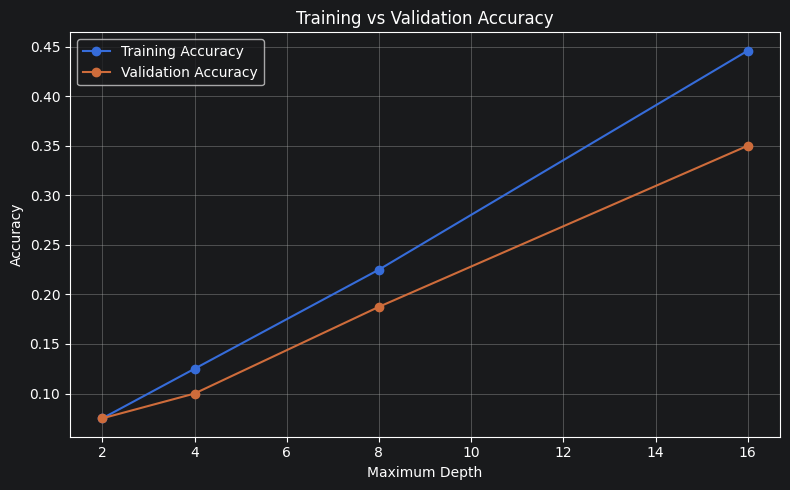

In [15]:
plot_df = results_df.groupby("Max Depth")[
    ["Training Accuracy", "Validation Accuracy"]
].mean()

plot_df.index = [
    "None" if pd.isna(d) else int(d)
    for d in plot_df.index
]

plot_df.plot(marker="o", figsize=(8, 5))

plt.xlabel("Maximum Depth")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:
# Best DT using Hyperparams turing

baselineModel = DecisionTreeClassifier(max_depth=None, min_samples_leaf=2, random_state=42)
baselineModel.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,2
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [18]:
import joblib
from joblib import Parallel, delayed

joblib.dump(baselineModel, '../Models/baseline_model.joblib')

# saving configuration metadata for reproducability
config = {
    "baseline_max_depth": None,
    "baseline_min_samples_leaf": 2,
}

joblib.dump(config, "../Models/model_config.joblib")

['Models/model_config.joblib']

In [19]:
baselineModel.tree_.n_node_samples

array([240,   6, 234,   6, 228,   6, 222,   6, 216, 210, 204,   6, 198,
         6, 192,   6, 186, 180, 174,   6, 168, 162,   6, 156,  16,  10,
         5,   5,   6, 140, 134,   7,   5,   2, 127,   6, 121,   6, 115,
         6, 109,  11,   5,   6,  98,   6,  92,   6,  86,  72,   6,  66,
        60,  54,   6,  48,  42,  36,  30,  24,   6,  18,   6,  12,   6,
         4,   2,   6,   6,   6,   6,   6,   6,   6,  14,   8,   6,   2,
         6,   6,   6,   6,   6,   6,   6])

Baseline Model Report:
Training Accuracy: 98.75%
Validation Accuracy: 67.50%
Test Accuracy: 56.25%
Number of Leaves: 43
Mean Samples per Leaf: 5.5814
Singleton Leaf Fraction: 0.0000



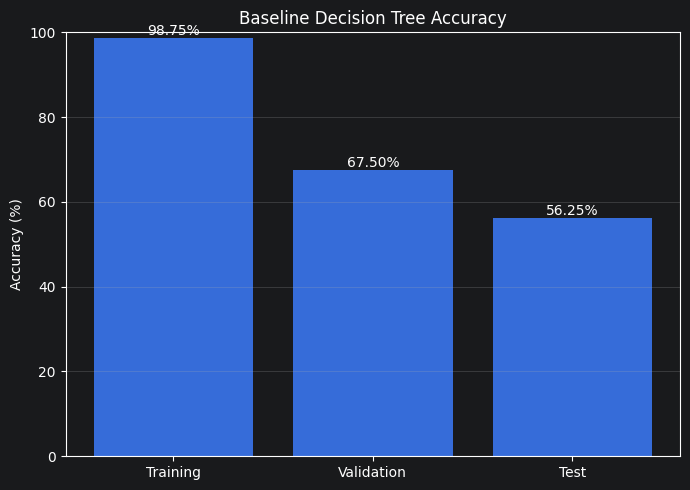

In [20]:
# Report for the baseline model
train_acc = baselineModel.score(X_train, y_train)
val_acc = baselineModel.score(X_valid, y_valid)
test_acc = baselineModel.score(X_test, y_test)

number_of_leaves = baselineModel.get_n_leaves()

# Identify the leaf nodes
tree = baselineModel.tree_
leaf_mask = (
    (tree.children_left == -1) &
    (tree.children_right == -1)
)

# Get the number of training samples in each leaf node
samples_per_leaf = tree.n_node_samples[leaf_mask]

# Required statistics
mean_samples_per_leaf = np.mean(samples_per_leaf)
singleton_leaf_fraction = np.mean(samples_per_leaf == 1)

# Print the baseline model report
print(
    f"Baseline Model Report:\n"
    f"Training Accuracy: {train_acc * 100:.2f}%\n"
    f"Validation Accuracy: {val_acc * 100:.2f}%\n"
    f"Test Accuracy: {test_acc * 100:.2f}%\n"
    f"Number of Leaves: {number_of_leaves}\n"
    f"Mean Samples per Leaf: {mean_samples_per_leaf:.4f}\n"
    f"Singleton Leaf Fraction: {singleton_leaf_fraction:.4f}\n"
)

# Plot training, validation, and test accuracy
labels = ["Training", "Validation", "Test"]
accuracies = [
    train_acc * 100,
    val_acc * 100,
    test_acc * 100
]

plt.figure(figsize=(7, 5))
bars = plt.bar(labels, accuracies)

plt.ylabel("Accuracy (%)")
plt.title("Baseline Decision Tree Accuracy")
plt.ylim(0, 100)
plt.bar_label(bars, fmt="%.2f%%")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

As depth increases, the decision tree becomes more complex and creates more splits. Training accuracy increases because the model learns more detailed patterns in the training data. Validation accuracy also increases in our results, but the gap between training and validation accuracy suggests possible overfitting at greater depths. Deeper trees generally have more leaves and fewer samples per leaf, making them more likely to memorize training examples.

In [21]:

def bagging(X_train, y_train, n_estimators, rng):
    trees = []
    distinct_counts = []
    n_samples_indices = []

    n_samples = X_train.shape[0]

    for i in range(n_estimators):

        # 1. Draw a bootstrap sample of the original training size
        sample_indices = rng.choice(
            X_train.shape[0],
            size=n_samples,
            replace=True
        )

        n_distinct = len(np.unique(sample_indices))
        distinct_counts.append(n_distinct)
        n_samples_indices.append(sample_indices)

        # 2. Generate a reproducible seed for this tree
        tree_seed = rng.integers(0, 2**31 - 1)

        # 3. Train a Decision Tree on the bootstrap sample
        model = DecisionTreeClassifier(
            max_depth=None,
            min_samples_leaf=2,
            random_state=tree_seed
        )

        model.fit(
            X_train[sample_indices],
            y_train[sample_indices]
        )

        trees.append(model)

    return {
        "trees": trees,
        "Data_indices": n_samples_indices,
        "distinct_counts": distinct_counts
    }


In [22]:
def get_bagging_votes(trees, X):
    """
    DESCR:
        A utility function to determine the class for each sample
        using each Decision Tree in the ensemble.

    ARGS:
        trees: Ensemble of Decision Trees
        X: Features of the dataset

    RETURNS:
        A matrix of shape (No. of trees, No. of samples in X)
    """
    return np.array([
        tree.predict(X) for tree in trees
    ]).T

In [23]:

def predict_bagging(trees, X):
    """
    DESCR:
        A utility function to determine the class for each sample
        using majority voting among all the decision trees
        present in the ensemble.

    ARGS:
        trees: Ensemble of Decision Trees
        X: Features of the dataset

    RETURNS:
        Class predicted by majority voting among trees
        in the bagged ensemble.
    """

    # Each row corresponds to one sample's predictions
    preds = get_bagging_votes(trees, X)

    # Select the most-voted class for each example
    y_pred = np.array([
        np.argmax(np.bincount(votes))
        for votes in preds
    ])

    return y_pred


In [24]:

def evaluate_bagging(
    trees,
    X_train, y_train,
    X_val, y_val,
    X_test, y_test
):
    """
    DESCR:
        A utility function to evaluate the model on training,
        validation, and test datasets.

    ARGS:
        trees: Ensemble of Decision Trees
        X_train: Features of the training dataset
        y_train: Labels of the training dataset
        X_val: Features of the validation dataset
        y_val: Labels of the validation dataset
        X_test: Features of the test dataset
        y_test: Labels of the test dataset

    RETURNS:
        A dictionary containing:
        - train_acc
        - val_acc
        - test_acc
    """

    # Training Accuracy
    train_acc = np.mean(
        y_train == predict_bagging(trees, X_train)
    )

    # Validation Accuracy
    val_acc = np.mean(
        y_val == predict_bagging(trees, X_val)
    )

    # Testing Accuracy
    test_acc = np.mean(
        y_test == predict_bagging(trees, X_test)
    )

    return {
        "train_acc": train_acc,
        "val_acc": val_acc,
        "test_acc": test_acc
    }


In [48]:
B_max_size = 200
B_size = [1, 5, 10, 25, 50, 100, 200]

bagging_result = bagging(X_train, y_train, n_estimators=B_max_size, rng=np.random.default_rng(seed=26001))
trees = bagging_result["trees"]
distinct_counts = bagging_result["distinct_counts"]

Bagging_results = []
for B in B_size:
    Bagging_results.append(evaluate_bagging(
        trees = trees[:B],
        X_train = X_train,
        y_train = y_train,
        X_val = X_valid,
        y_val = y_valid,
        X_test = X_test,
        y_test = y_test
    ))
    Bagging_results[-1]["Avg Distinct Samples"] = np.mean(distinct_counts[:B])
results_df = pd.DataFrame(Bagging_results, index=B_size)

In [49]:
results_df

,train_acc,val_acc,test_acc,Avg Distinct Samples
1,0.712500,0.3875,0.3250,159.00
5,0.970833,0.6000,0.5250,151.80
10,0.975000,0.7250,0.5875,151.60
25,1.000000,0.8500,0.7250,151.72
50,1.000000,0.8875,0.8250,153.06
100,1.000000,0.8750,0.8500,152.39
200,1.000000,0.9000,0.8750,152.26


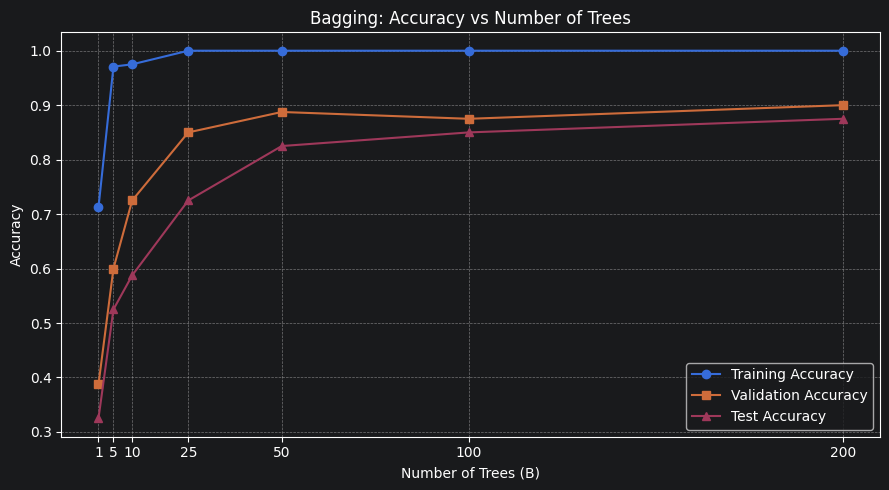

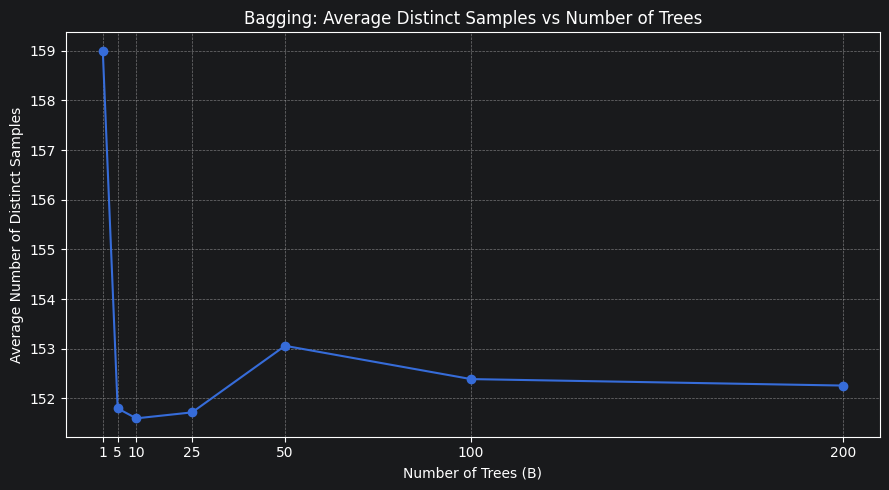

In [50]:
# Plot accuracy vs number of trees
plt.figure(figsize=(9, 5))

plt.plot(
    results_df.index,
    results_df["train_acc"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    results_df.index,
    results_df["val_acc"],
    marker="s",
    label="Validation Accuracy"
)

plt.plot(
    results_df.index,
    results_df["test_acc"],
    marker="^",
    label="Test Accuracy"
)

plt.xlabel("Number of Trees (B)")
plt.ylabel("Accuracy")
plt.title("Bagging: Accuracy vs Number of Trees")
plt.xticks(B_size)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


#Plot average distinct samples vs number of trees
plt.figure(figsize=(9, 5))

plt.plot(
    results_df.index,
    results_df["Avg Distinct Samples"],
    marker="o"
)

plt.xlabel("Number of Trees (B)")
plt.ylabel("Average Number of Distinct Samples")
plt.title("Bagging: Average Distinct Samples vs Number of Trees")
plt.xticks(B_size)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

In [51]:
n = X_train.shape[0]

theoretical_distinct = n * (1 - (1 - 1/n)**n)
print("Theoretical expectation:", theoretical_distinct)

Theoretical expectation: 151.8931938460841


In [52]:
#Part(c):

def oob_accuracy(trees, bootstrap_indices, X_train, y_train):
    oob_votes = [[] for _ in range(len(y_train))]

    for i in range(len(trees)):
        tree = trees[i]
        sample_indices = bootstrap_indices[i]

        oob_mask = np.ones(X_train.shape[0], dtype=bool)
        oob_mask[sample_indices] = False  # Mark the bootstrap sample indices as False

        X_oob = X_train[oob_mask]
        y_oob = y_train[oob_mask]
        y_pred_oob = tree.predict(X_oob)

        oob_indices = np.flatnonzero(oob_mask)

        for idx, pred in zip(oob_indices, y_pred_oob):
            oob_votes[idx].append(pred)

    # Calculate the OOB accuracy
    correct_predictions = 0
    total_oob_samples = 0
    for i in range(len(y_train)):
        if oob_votes[i]:  # If there are OOB votes for this sample
            total_oob_samples += 1
            majority_vote = np.argmax(np.bincount(oob_votes[i]))
            if majority_vote == y_train[i]:
                correct_predictions += 1
    oob_accuracy = correct_predictions / total_oob_samples if total_oob_samples > 0 else 0
    return oob_accuracy

In [53]:
# Calculate OOB accuracy for different numbers of trees
oob_results = []

for B in B_size:
    oob_acc = oob_accuracy(
        trees[:B],
        bagging_result["Data_indices"][:B],
        X_train,
        y_train
    )

    oob_results.append({
        "B": B,
        "OOB Accuracy": oob_acc
    })

# Create a DataFrame to store the results
oob_results_df = pd.DataFrame(oob_results)

# Display the results
oob_results_df

,B,OOB Accuracy
0,1,0.259259
1,5,0.304147
2,10,0.402542
3,25,0.587500
4,50,0.687500
5,100,0.716667
6,200,0.783333


In [54]:
def pairwise_disagreement(trees, X):
    # Get predictions from all trees
    predictions = get_bagging_votes(trees, X)
    B = predictions.shape[1]

    # At least two trees are required
    if B < 2:
        return np.nan

    # Total number of tree pairs
    total_pairs = B * (B - 1) / 2
    disagreements = []

    # Calculate disagreement for each sample
    for row in predictions:
        _, counts = np.unique(row, return_counts=True)

        agreeing = np.sum(counts * (counts - 1) / 2)
        disagreeing_pairs = total_pairs - agreeing

        disagreements.append(disagreeing_pairs / total_pairs)

    # Return average pairwise disagreement
    return np.mean(disagreements)

In [55]:
# Calculate average pairwise disagreement for different numbers of trees
pairwise_results = []

for B in B_size:
    apd = pairwise_disagreement(trees[:B], X_train)

    pairwise_results.append({
        "B": B,
        "Average Pairwise Disagreement": apd
    })

# Create a DataFrame to store the results
pairwise_results_df = pd.DataFrame(pairwise_results)

# Display the results
pairwise_results_df

,B,Average Pairwise Disagreement
0,1,NaN
1,5,0.498333
2,10,0.484259
3,25,0.488514
4,50,0.477765
5,100,0.478531
6,200,0.477561


In [33]:
def mean_vote_margin(trees, X):
    # Get predictions from all trees
    predictions = get_bagging_votes(trees, X)
    B = predictions.shape[1]

    margins = []

    # Calculate the vote margin for each sample
    for row in predictions:
        # Count votes for each class (40 classes)
        votes = np.bincount(row, minlength=40)

        # Find the largest and second-largest vote counts
        sorted_votes = np.sort(votes)[::-1]
        largest = sorted_votes[0]
        second_largest = sorted_votes[1] if len(sorted_votes) > 1 else 0

        # Calculate the winning and runner-up vote fractions
        winning_fraction = largest / B
        runner_up_fraction = second_largest / B

        # Calculate the vote margin
        margin = winning_fraction - runner_up_fraction

        margins.append(margin)

    # Return the mean vote margin
    return np.mean(margins)

In [34]:
# Calculate mean vote margin for different numbers of trees
mean_votes_results = []

for B in B_size:
    margin = mean_vote_margin(trees[:B], X_train)

    mean_votes_results.append({
        "B": B,
        "Mean Vote Margin": margin
    })

# Create a DataFrame to store the results
mean_votes_results_df = pd.DataFrame(mean_votes_results)

# Display the results
mean_votes_results_df

,B,Mean Vote Margin
0,1,1.000000
1,5,0.557500
2,10,0.581250
3,25,0.627167
4,50,0.642250
5,100,0.653583
6,200,0.655792


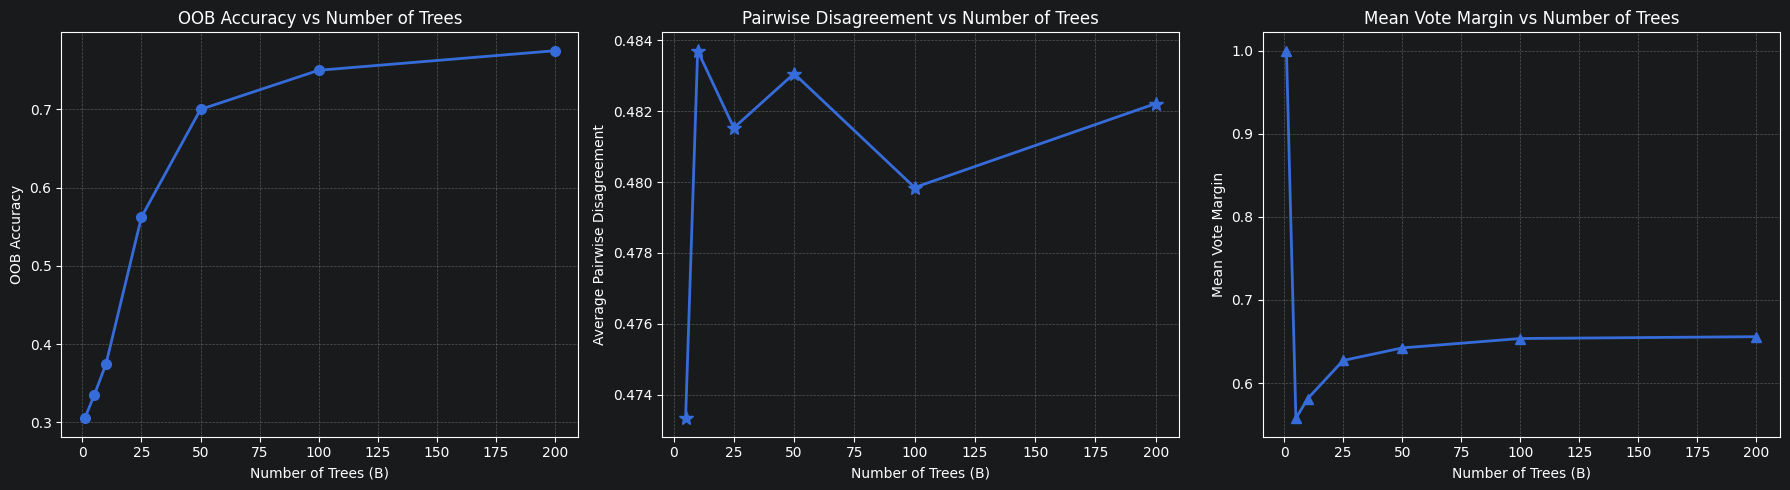

In [35]:
# Plot OOB accuracy, pairwise disagreement, and mean vote margin
plt.figure(figsize=(18, 5))

# 1. OOB Accuracy
plt.subplot(1, 3, 1)
plt.plot(
    oob_results_df["B"],
    oob_results_df["OOB Accuracy"],
    marker="o",
    linewidth=2,
    markersize=7
)
plt.xlabel("Number of Trees (B)")
plt.ylabel("OOB Accuracy")
plt.title("OOB Accuracy vs Number of Trees")
plt.grid(True, linestyle="--", alpha=0.4)

# 2. Average Pairwise Disagreement
plt.subplot(1, 3, 2)
plt.plot(
    pairwise_results_df["B"],
    pairwise_results_df["Average Pairwise Disagreement"],
    marker="*",
    linewidth=2,
    markersize=10
)
plt.xlabel("Number of Trees (B)")
plt.ylabel("Average Pairwise Disagreement")
plt.title("Pairwise Disagreement vs Number of Trees")
plt.grid(True, linestyle="--", alpha=0.4)

# 3. Mean Vote Margin
plt.subplot(1, 3, 3)
plt.plot(
    mean_votes_results_df["B"],
    mean_votes_results_df["Mean Vote Margin"],
    marker="^",
    linewidth=2,
    markersize=7
)
plt.xlabel("Number of Trees (B)")
plt.ylabel("Mean Vote Margin")
plt.title("Mean Vote Margin vs Number of Trees")
plt.grid(True, linestyle="--", alpha=0.4)

# Improve overall layout
plt.tight_layout()
plt.show()

In [36]:
results_df

,train_acc,val_acc,test_acc,Avg Distinct Samples
1,0.704167,0.4375,0.4375,145.000
5,0.933333,0.5625,0.5000,150.600
10,0.991667,0.6625,0.6500,151.800
25,1.000000,0.8625,0.7500,151.840
50,1.000000,0.9250,0.7625,151.860
100,1.000000,0.9375,0.8000,152.110
200,1.000000,0.9250,0.8250,151.725


In [57]:
# Saving model to local dir ./Models
final_B = 50

# using first 50 trees from existing ensemble trees
final_bagged_trees = trees[:final_B]

joblib.dump(final_bagged_trees, 'Models/bagging_model_B50.joblib')

# Save configuration metadata for reproducibility
config = {
    "baseline_max_depth": None,
    "baseline_min_samples_leaf": 2,
    "bagging_max_depth": None,
    "bagging_min_samples_leaf": 2,
    "bagging_n_estimators": 50,
    "random_seed": 26001,
}

joblib.dump(config, "Models/model_config.joblib")

['Models/model_config.joblib']

In [58]:
#Part(d)
def bagging_confidence(trees, X):
    # Get predictions from all trees
    votes = get_bagging_votes(trees, X)

    confidence = []

    # Calculate confidence for each sample
    for row in votes:
        counts = np.bincount(row, minlength=40)

        # Maximum vote fraction across all classes
        confidence.append(counts.max() / len(trees))

    # Return confidence scores as a NumPy array
    return np.array(confidence)

In [59]:
# Create a copy of the test images and reshape them to 64 × 64
X_masked_test = X_test.reshape(-1, 64, 64).copy()

# Mask the central region of each image
X_masked_test[:, 24:40, 24:40] = 0

# Flatten the images back to 4096 features
X_masked_test = X_masked_test.reshape(-1, 4096)

# Display the resulting shape
X_masked_test.shape

(80, 4096)

,Model,Clean Accuracy,Clean Mean Confidence,Masked Accuracy,Masked Mean Confidence
0,Single Tree,0.5625,0.9875,0.3625,0.99375
1,Bagging (B=50),0.8250,0.3725,0.6625,0.26200


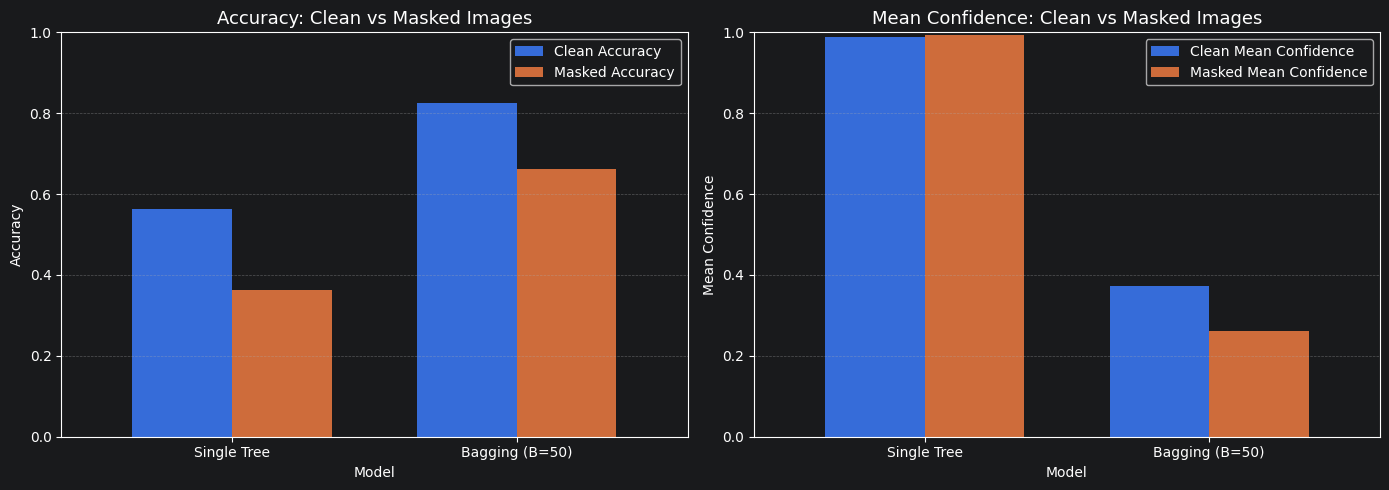

In [60]:
base_clean_accuracy = baselineModel.score(X_test, y_test)

base_clean_confidence = (
    baselineModel.predict_proba(X_test)
    .max(axis=1)
    .mean()
)

bagged_clean_preds = predict_bagging(final_bagged_trees, X_test)
bagged_clean_accuracy = np.mean(bagged_clean_preds == y_test)

bagged_clean_confidence = bagging_confidence(
    final_bagged_trees, X_test
).mean()


base_masked_accuracy = baselineModel.score(X_masked_test, y_test)

base_masked_confidence = (
    baselineModel.predict_proba(X_masked_test)
    .max(axis=1)
    .mean()
)

bagged_masked_preds = predict_bagging(
    final_bagged_trees, X_masked_test
)
bagged_masked_accuracy = np.mean(bagged_masked_preds == y_test)

bagged_masked_confidence = bagging_confidence(
    final_bagged_trees, X_masked_test
).mean()


comparison_df = pd.DataFrame({
    "Model": ["Single Tree", "Bagging (B=50)"],
    "Clean Accuracy": [
        base_clean_accuracy, bagged_clean_accuracy
    ],
    "Clean Mean Confidence": [
        base_clean_confidence, bagged_clean_confidence
    ],
    "Masked Accuracy": [
        base_masked_accuracy, bagged_masked_accuracy
    ],
    "Masked Mean Confidence": [
        base_masked_confidence, bagged_masked_confidence
    ]
})

display(comparison_df)


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

comparison_df.set_index("Model")[
    ["Clean Accuracy", "Masked Accuracy"]
].plot(kind="bar", ax=axes[0], width=0.7)

axes[0].set_title("Accuracy: Clean vs Masked Images", fontsize=13)
axes[0].set_xlabel("Model")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=0)
axes[0].grid(axis="y", linestyle="--", alpha=0.4)
axes[0].legend(loc="best")

comparison_df.set_index("Model")[
    ["Clean Mean Confidence", "Masked Mean Confidence"]
].plot(kind="bar", ax=axes[1], width=0.7)

axes[1].set_title("Mean Confidence: Clean vs Masked Images", fontsize=13)
axes[1].set_xlabel("Model")
axes[1].set_ylabel("Mean Confidence")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)
axes[1].legend(loc="best")

plt.tight_layout()
plt.show()

In [44]:
tree_preds = baselineModel.predict(X_test)
bagging_preds = predict_bagging(final_bagged_trees, X_test)

# Find cases where the tree is wrong but bagging is correct
correct_mask = (tree_preds != y_test) & (bagging_preds == y_test)
correct_indices = np.where(correct_mask)[0]

print("Indices where bagging corrects the tree:", correct_indices)
print("True labels:", y_test[correct_indices])
print("Tree Predictions:", tree_preds[correct_indices])
print("Bagging predictions:", bagging_preds[correct_indices])

# Select two examples
two_corrected = correct_indices[:2]

Indices where bagging corrects the tree: [ 0  1  3  6 14 16 20 23 25 27 31 34 41 43 48 49 55 57 59 60 62 73]
True labels: [ 0  0  1  3  7  8 10 11 12 13 15 17 20 21 24 24 27 28 29 30 31 36]
Tree Predictions: [ 7 16 30 38 11  9 29  8  6 26  0  0 13 28 17 37 24  2 20 12  0 25]
Bagging predictions: [ 0  0  1  3  7  8 10 11 12 13 15 17 20 21 24 24 27 28 29 30 31 36]


In [45]:
# Find cases where both models are wrong
both_wrong_mask = (tree_preds != y_test) & (bagging_preds != y_test)
both_wrong_indices = np.where(both_wrong_mask)[0]

print("Indices where both models are wrong:", both_wrong_indices)
print("True labels:", y_test[both_wrong_indices])
print("Tree predictions:", tree_preds[both_wrong_indices])
print("Bagging predictions:", bagging_preds[both_wrong_indices])

# Select two examples
two_both_wrong = both_wrong_indices[:2]

Indices where both models are wrong: [ 5  7  8 18 19 24 30 32 33 68 71 74 79]
True labels: [ 2  3  4  9  9 12 15 16 16 34 35 37 39]
Tree predictions: [34 12 22 11  8 17  1 24  3 20 30  0  4]
Bagging predictions: [24  0  2  8  4  1  5  5  5  8 14 39  4]


In [46]:
def show_vote_counts(indices, X, y_true, tree_preds, trees):
    all_votes = get_bagging_votes(trees, X)

    for idx in indices:
        votes = all_votes[idx]
        counts = np.bincount(votes, minlength=40)

        print(f"\nTest Index: {idx}")
        print(f"True identity: {y_true[idx]}")
        print(f"Tree prediction: {tree_preds[idx]}")
        print(f"Bagging prediction: {np.argmax(counts)}")
        print(f"Winning vote count: {counts.max()}")

        print(
            "Non-zero class votes:",
            {
                i: int(c)
                for i, c in enumerate(counts)
                if c > 0
            }
        )


show_vote_counts(
    two_corrected, X_test, y_test,
    tree_preds, final_bagged_trees
)

show_vote_counts(
    two_both_wrong, X_test, y_test,
    tree_preds, final_bagged_trees
)


Test Index: 0
True identity: 0
Tree prediction: 7
Bagging prediction: 0
Winning vote count: 19
Non-zero class votes: {0: 19, 4: 1, 5: 1, 7: 12, 9: 6, 10: 2, 13: 1, 14: 1, 15: 2, 17: 3, 31: 1, 39: 1}

Test Index: 1
True identity: 0
Tree prediction: 16
Bagging prediction: 0
Winning vote count: 20
Non-zero class votes: {0: 20, 1: 3, 5: 1, 7: 3, 9: 1, 11: 1, 12: 3, 14: 1, 15: 4, 16: 9, 27: 1, 32: 1, 35: 1, 39: 1}

Test Index: 5
True identity: 2
Tree prediction: 34
Bagging prediction: 24
Winning vote count: 5
Non-zero class votes: {0: 1, 1: 2, 2: 3, 3: 1, 4: 1, 5: 1, 8: 3, 11: 1, 12: 3, 13: 1, 14: 1, 17: 2, 19: 1, 20: 3, 22: 1, 23: 1, 24: 5, 25: 1, 26: 2, 27: 1, 29: 1, 30: 1, 32: 1, 33: 1, 34: 4, 37: 4, 39: 3}

Test Index: 7
True identity: 3
Tree prediction: 12
Bagging prediction: 0
Winning vote count: 5
Non-zero class votes: {0: 5, 2: 2, 3: 5, 4: 2, 6: 3, 7: 2, 9: 2, 12: 2, 14: 2, 15: 2, 16: 2, 17: 2, 20: 3, 22: 1, 23: 1, 27: 1, 28: 1, 31: 1, 34: 2, 35: 5, 39: 4}
